# Einstieg in Jupyter Notebooks

Dieses Notebook führt dich mit einem kleinen Beispiel in Jupyter ein.

## 1. Was ist ein Jupyter Notebook?

Ein Jupyter Notebook ist ein interaktives Dokument. Es verbindet ausführbaren Code mit erklärendem Text, Formeln und Visualisierungen. So kannst du zum Beispiel Daten untersuchen, Berechnungen ausprobieren und direkt daneben festhalten, was du herausgefunden hast.

Ein Notebook besteht aus Zellen. Du führst einzelne Zellen aus und siehst das Ergebnis direkt darunter.

## 2. Installation und Start

Falls Jupyter noch nicht installiert ist, installierst du es in einem Terminal:

```bash
pip install notebook
```

Wechsle im Terminal in den Ordner, in dem du arbeiten möchtest, und starte Jupyter:

```bash
jupyter notebook
```

Jupyter öffnet dann eine Seite im Browser. Dort kannst du ein vorhandenes Notebook öffnen oder ein neues Python-Notebook anlegen.

## 3. Zellen erstellen und ausführen

Eine Zelle enthält entweder Python-Code oder Text in Markdown. Über die Schaltfläche **+** fügst du eine Zelle hinzu. Im Zelltyp-Menü wechselst du zwischen **Code** und **Markdown**. Markdown eignet sich für Überschriften und Erklärungen; Code-Zellen führen Python aus.

Drücke **Shift+Enter**, um die aktuelle Zelle auszuführen und zur nächsten zu wechseln. Die Ausgabe erscheint direkt unter der Code-Zelle. Code-Zellen teilen sich einen laufenden Python-Kernel: Variablen aus einer bereits ausgeführten Zelle stehen späteren Zellen zur Verfügung. Führe die Zellen deshalb der Reihe nach aus. Nach einem Kernel-Neustart musst du sie erneut ausführen.

## 4. Ein einfaches Python-Beispiel: Rechnen mit Zahlen

In der nächsten Code-Zelle speichern wir zwei Zahlen in Variablen und addieren sie. Die letzte Zeile gibt das Ergebnis aus.

Führe die Zelle mit **Shift+Enter** aus:

In [1]:
a = 3
b = 5
print(a + b)

8


## 5. Daten mit Matplotlib visualisieren

Mit Matplotlib kannst du Werte als Diagramm darstellen. Das folgende Beispiel verbindet drei x-Werte mit drei y-Werten. Falls Matplotlib in deiner Python-Umgebung noch fehlt, installiere es im Terminal mit `pip install matplotlib`.

Die Achsenbeschriftungen und der Titel machen das Diagramm leichter lesbar:

Gespeichert: liniendiagramm.png


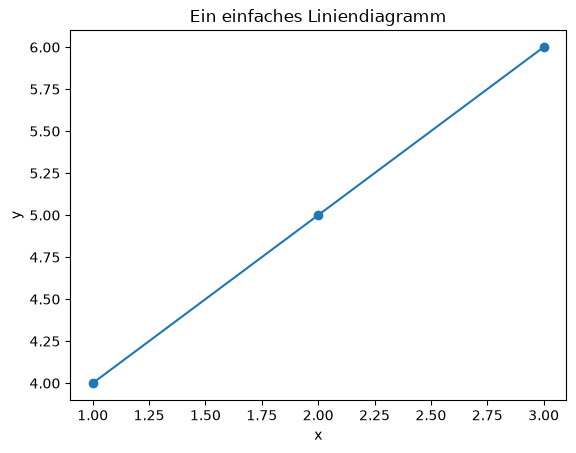

In [9]:
import matplotlib.pyplot as plt

x_werte = [1, 2, 3]
y_werte = [4, 5, 6]

plt.plot(x_werte, y_werte, marker="o")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Ein einfaches Liniendiagramm")
plt.savefig("liniendiagramm.png", dpi=150, bbox_inches="tight")
print("Gespeichert: liniendiagramm.png")
plt.show()

## 6. Ein etwas größeres Beispiel: Noten auswerten

Hier speichern wir mehrere Namen und Noten in einem Wörterbuch. Python berechnet den Durchschnitt, findet die beste Note und zählt mit einer Bedingung, wie viele Personen bestanden haben. In diesem Beispiel ist **1,0 die beste Note** und **4,0 noch bestanden**.

Ändere anschließend einzelne Noten und führe die Zelle erneut aus, um zu sehen, wie sich die Auswertung verändert.

In [8]:
noten = {
    "Anna": 1.7,
    "Ben": 1.6,
    "Clara": 2.0,
    "David": 3.0,
}

durchschnitt = sum(noten.values()) / len(noten)
beste_person = min(noten, key=noten.get)
bestanden = [person for person, note in noten.items() if note <= 4.0]

print(f"Durchschnittsnote: {durchschnitt:.2f}")
print(f"Beste Note: {noten[beste_person]:.1f} ({beste_person})")
print(f"Bestanden: {len(bestanden)} von {len(noten)}")

Durchschnittsnote: 2.08
Beste Note: 1.6 (Ben)
Bestanden: 4 von 4


## 7. CSV-Daten einlesen und Ausgaben untersuchen

CSV-Dateien sind einfache Tabellen, die häufig Daten aus Tabellenprogrammen oder Exporten enthalten. Hier simulieren wir eine kleine Datei direkt im Notebook und lesen sie mit Pythons eingebautem `csv`-Modul ein. Danach fassen wir die Beträge nach Kategorie zusammen und zeichnen ein Balkendiagramm.

Die Beispieldaten sind direkt im Code enthalten; du brauchst keine Datei herunterzuladen.

In [4]:
import csv
from io import StringIO

csv_text = """datum,kategorie,betrag
2026-10-01,Essen,12.50
2026-10-02,Transport,3.20
2026-10-03,Essen,8.75
2026-10-04,Buecher,24.90
2026-10-05,Transport,3.20
2026-10-06,Essen,15.10
"""

buchungen = list(csv.DictReader(StringIO(csv_text)))
for buchung in buchungen:
    buchung["betrag"] = float(buchung["betrag"])

print(f"Eingelesene Buchungen: {len(buchungen)}")
print("Erster Eintrag:", buchungen[0])

Eingelesene Buchungen: 6
Erster Eintrag: {'datum': '2026-10-01', 'kategorie': 'Essen', 'betrag': 12.5}


In [ ]:
summen_pro_kategorie = {}
for buchung in buchungen:
    kategorie = buchung["kategorie"]
    summen_pro_kategorie[kategorie] = (
        summen_pro_kategorie.get(kategorie, 0) + buchung["betrag"]
    )

gesamtausgaben = sum(summen_pro_kategorie.values())
teuerste_kategorie = max(summen_pro_kategorie, key=summen_pro_kategorie.get)
durchschnitt_pro_buchung = gesamtausgaben / len(buchungen)

for kategorie, summe in sorted
    summen_pro_kategorie.items(), key=lambda eintrag: eintrag[1], reverse=True
):
    print(f"{kategorie}: {summe:.2f} EUR")

print(f"\nGesamt: {gesamtausgaben:.2f} EUR")
print(f"Durchschnitt je Buchung: {durchschnitt_pro_buchung:.2f} EUR")
print(f"Größte Kategorie: {teuerste_kategorie}")

Essen: 36.35 EUR
Buecher: 24.90 EUR
Transport: 6.40 EUR

Gesamt: 67.65 EUR
Durchschnitt je Buchung: 11.28 EUR
Größte Kategorie: Essen


Gespeichert: ausgaben_nach_kategorie.png


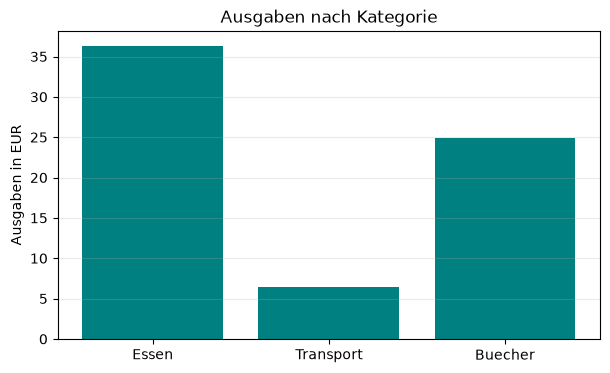

In [10]:
kategorien = list(summen_pro_kategorie.keys())
kategorie_summen = list(summen_pro_kategorie.values())

plt.figure(figsize=(7, 4))
plt.bar(kategorien, kategorie_summen, color="teal")
plt.ylabel("Ausgaben in EUR")
plt.title("Ausgaben nach Kategorie")
plt.grid(axis="y", alpha=0.25)
plt.savefig("ausgaben_nach_kategorie.png", dpi=150, bbox_inches="tight")
print("Gespeichert: ausgaben_nach_kategorie.png")
plt.show()

## Zum Ausprobieren

1. Ändere im Notenbeispiel eine Note. Wie verändern sich Durchschnitt und Anzahl der bestandenen Personen?
2. Ergänze im CSV-Beispiel eine neue Buchung, zum Beispiel `2026-10-07,Freizeit,18.00`.
3. Führe danach die Zellen zum Einlesen, Zusammenfassen und Zeichnen erneut aus. So siehst du, wie eine Änderung an den Rohdaten die ganze Auswertung beeinflusst.

Das ist ein typischer Jupyter-Arbeitsablauf: Daten verändern, einzelne Schritte ausführen, Ergebnis prüfen und die Auswertung bei Bedarf anpassen.